In [1]:
import sys

sys.path.append("../src")
from data_validation import validate_dataframe
import glob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.errors import EmptyDataError
import seaborn as sns
from typing import Literal

In [2]:
first_20_path = r"C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\data\processed\yahoo_finance\first_20_companies"

In [3]:
def get_dataset(filepath: str, file_num: int) -> pd.DataFrame:
    """Helper function to accessing csv files in directory

    Args:
        filepath (str): directory path to containing csv files
        file_num (int): list index number of the file list

    Returns:
        pd.DataFrame: pandas dataframe
    """
    dataset_dir = glob.glob(f"{filepath}/*.csv")

    df = pd.read_csv(dataset_dir[file_num])

    return df

In [4]:
master_df = get_dataset(first_20_path,0)

In [5]:
def check_monotonic(
    dataset: pd.DataFrame
    ) -> bool:
    """Check if dates are monotonic or not

    Args:
        dataset (pd.DataFrame): current pandas dataset(note: date column must be datetime format)

    Raises:
        EmptyDataError: raised when dataset is empty

    Returns:
        bool: True if monotonic else False
    """

    validate_dataframe(dataset)

    date_col = [col for col in dataset.columns]

    for column in date_col:
        if pd.api.types.is_datetime64_any_dtype(dataset[column]):
            is_increasing = dataset[column].is_monotonic_increasing

            is_decreasing = dataset[column].is_monotonic_decreasing

            return is_increasing or is_decreasing

    return False

In [6]:
def column_check(
    dataset: pd.DataFrame
    ) -> bool:
    """Checks required columns availability

    Args:
        dataset (pd.DataFrame): A pandas dataframe

    Returns:
        bool: returns True for "OHLCV" including "Date" & 'Ticker' is available else False
    """
    
    validate_dataframe(dataset)
    
    req_col = ['Close', 'High', 'Low', 'Open', 'Volume', 'Ticker', 'Date']
    
    clean_req = []
    
    for col in req_col:
        clean_req.append(col.strip().lower()) 
        
    actual_col = [col for col in dataset.columns]

    clean_actual = []
    
    for col in actual_col:
        clean_actual.append(col.strip().lower()) 
        
        
    required = set(clean_req)
    actual = set(clean_actual)
    
    if required.issubset(actual):
        return True

    return False

In [7]:
def convert_date(
    dataset: pd.DataFrame, date_col: str, errors: Literal["raise", "coerce"] = "coerce"
) -> pd.DataFrame:
    """Convert 'Date' column in the dataset.
        Warning :  Using errors='coerce' converts invalid date values to NaT.

    Args:
        dataset (pd.DataFrame): The input pandas DataFrame.
        date_col (str): Name of the column to convert. Case-sensitive.
        errors (Literal['raise', 'coerce']): Determines how invalid date values
        are handled. Defaults to 'coerce'.
        - 'raise': Raises an exception when an invalid date is encountered.
        - 'coerce': Converts invalid date values to NaT.

    Raises:
        EmptyDataError: raises error if dataset is empty
        KeyError: raises error if the date column is not present in the dataset

    Returns:
        pd.DataFrame: The DataFrame with the specified column converted to pandas datetime.
    """
    validate_dataframe(dataset)

    if date_col not in dataset.columns:
        raise KeyError(f"No {date_col} was found in the dataset")

    dataset[date_col] = pd.to_datetime(dataset[date_col], errors=errors)

    return dataset

In [8]:
def round_float(dataset: pd.DataFrame, r: int = 2) -> pd.DataFrame:
    """
    Round floating-point columns in a Pandas DataFrame.

    Rounds all floating-point columns to the specified decimal
    precision. The default precision is 2 decimal places.

    Args:
        dataset (pd.DataFrame): The DataFrame to be modified.
        r (int): Number of decimal places to retain. Defaults to 2.

    Raises:
        TypeError: If dataset is not a DataFrame or r is not an integer.
        ValueError: If r is negative.
        EmptyDataError: If the provided DataFrame is empty.

    Returns:
        pd.DataFrame: The modified DataFrame with rounded float columns.
    """
    validate_dataframe(dataset)

    if isinstance(r, bool) or isinstance(r, float):
        raise TypeError(
            f"The arg {r} provided must be an integer, got {type(r).__name__}"
        )

    if r < 0:
        raise ValueError("The rounding parameter 'r' must be 0 or greater.")

    columns = [col for col in dataset.columns]

    for col in columns:
        if pd.api.types.is_float_dtype(dataset[col]):
            dataset[col] = round(dataset[col], r)

    return dataset

# Short-Term Trends

**Time Horizon:** Intraday (minutes/hours) to several weeks or months.

**Key Indicators:**
- MA20 (20-period moving average)
- Daily returns
- Volatility
- Trading volume spikes
- News sentiment

**Financial Significance:** Helps identify recent momentum and potential trading opportunities.

In [9]:
def duplicate_date_check(dataset: pd.DataFrame):
    """Check and raises error if duplicate dates are found

    Args:
        dataset (pd.DataFrame): a pandas dataframe

    Raises:
        ValueError: raises if duplicate dates are found
    """
    for col in dataset.columns:
        if pd.api.types.is_datetime64_any_dtype(dataset[col]):
            if dataset[col].duplicated().sum() > 0:
                raise ValueError(f"Duplicate dates found in column: {col}")

In [10]:
def calculate_moving_average(
    dataset: pd.DataFrame,
    ) -> pd.DataFrame:
    """Calculates Moving Averages from Short to Long Term Trends (MA20,MA50,MA200) and appends to existing dataframe

    Args:
        dataset (pd.DataFrame): a pandas dataframe

    Raises:
        ValueError: raises if dataset if not monotonically increasing
        validate_dataframe (function): raises errors if dataset is empty or not a pandas dataframe

    Returns:
        pd.DataFrame: a pandas dataframe
    """
    
    validate_dataframe(dataset)
    
    convert_date(dataset,'Date') # default error = 'coerce'
    
    # important checks before rolling average
    if not check_monotonic(dataset):
        raise ValueError('The dataframe must be monotonically increasing')
    
    # duplicate check 
    duplicate_date_check(dataset)
    
    dataset['MA20'] = dataset['Close'].rolling(window=20).mean()    
    dataset['MA50'] = dataset['Close'].rolling(window=50).mean()    
    dataset['MA200'] = dataset['Close'].rolling(window=200).mean()    
    
    return dataset

Short term analysis (MA20) helps identify recent momentum potential opportunity whereas long term analysis (MA200) is widely used and respected trend indicator.

A new data frame containing the selected features was createdpost calculation using “Featured used” columns. TheClose price, MA20, MA50, and MA200were plotted on a single line chart usingDate as the x-axis. Plotting all series on the same graph enables direct comparison of price movements and moving-average relationships, making bullish periods, bearish periods, and crossover signals easier to identify.



In [11]:
df = get_dataset(first_20_path,0)


In [12]:
pipe = (convert_date(df,'Date'),
check_monotonic(df),
column_check(df),
calculate_moving_average(df),
round_float(df)
)

In [13]:
#For automatic plotting in Jupyter, can be removed as required
%matplotlib widget 

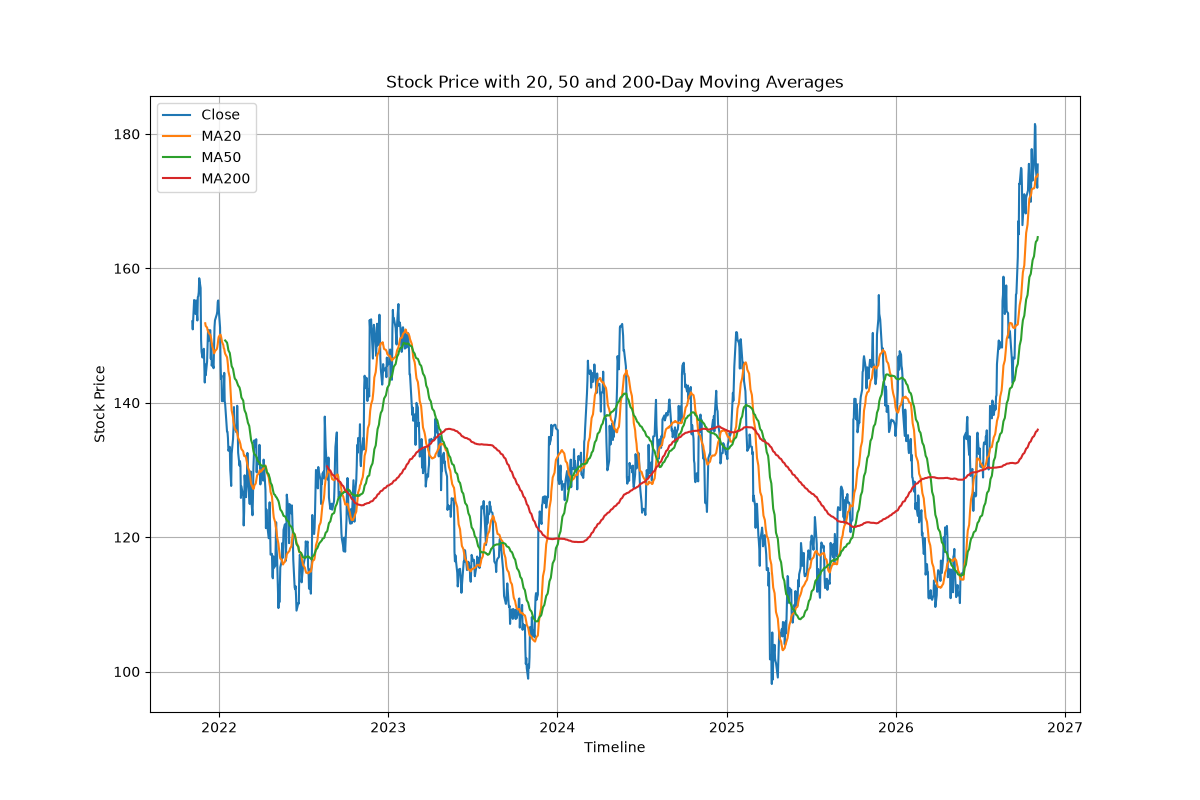

In [14]:
plt.figure(figsize=(12, 8))
plt.plot(df['Date'],df['Close'],label = 'Close')
plt.plot(df['Date'],df['MA20'],label = 'MA20')
plt.plot(df['Date'],df['MA50'],label = 'MA50')
plt.plot(df['Date'],df['MA200'],label = 'MA200')
plt.grid(True)
plt.xlabel('Timeline')
plt.ylabel('Stock Price')
plt.title("Stock Price with 20, 50 and 200-Day Moving Averages")
plt.legend()
plt.show()


# Definitions and interpretations

*Bearish Period*: Price < MA20 < MA50 < MA20
-   *coordinates (approx)* = (2026,181.5)
-  *Financial Interpretation*:  This structure suggests persistent weak and negative sentiment.

*Bullish Period*: Price > MA20 > MA50 > MA200 
- *coordinates (approx)*= (2023,99)
- *Financial Interpretation*: Investors generally interpret this alignment as strong upward momentum and positive market sentiment

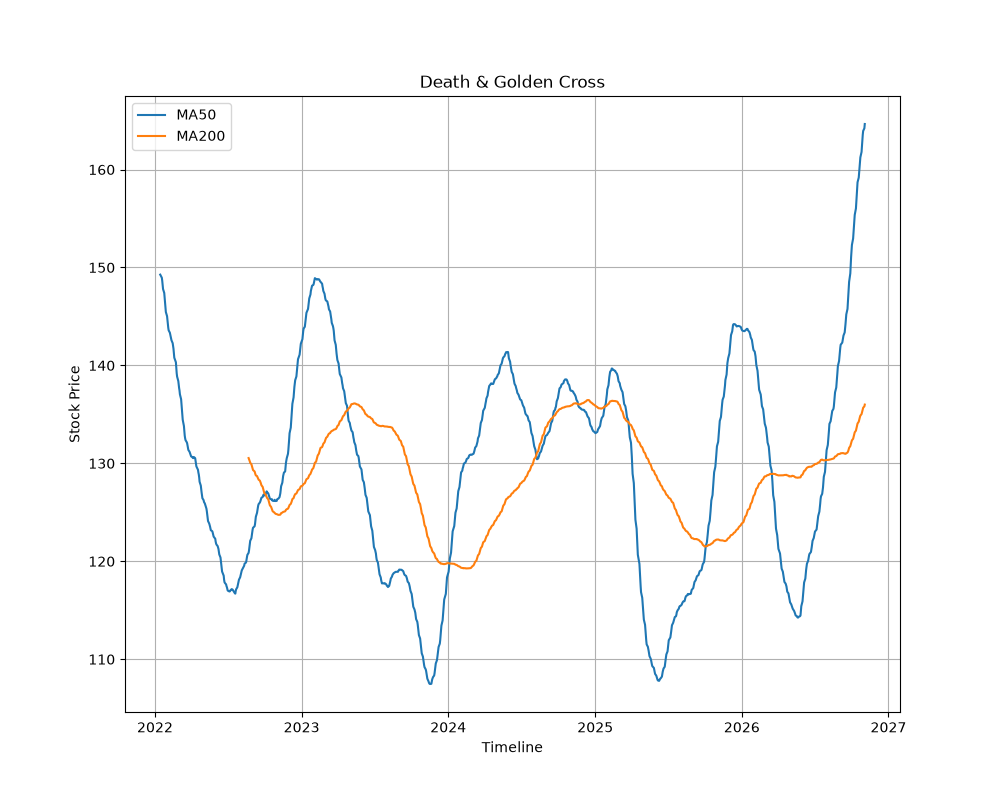

In [15]:
plt.figure(figsize=(10,8))
plt.plot(df['Date'],df['MA50'],label = "MA50")
plt.plot(df['Date'],df['MA200'],label = "MA200")
plt.grid(True)
plt.xlabel("Timeline")
plt.ylabel("Stock Price")
plt.title("Death & Golden Cross")
plt.legend()
plt.show()


# Definitions and interpretations

*Golden Cross*: This occurs when MA50 and MA200 intersect (MA50 crosses above MA200).
- *Financial Interpretation*:The medium-term trend has become stronger than the long-term trend, often signaling the beginning of a bullish market.

*Death Cross*: This occurs when MA50 crosses below the MA200.
- *Financial Interpretation*: The medium-term trend has weakened relative to the long-term trend, often signaling a bearish market phase..

**Note**: ***Golden Cross(Bullish)*** always occurs when MA50 is above MA200 and ***Death Cross (Bearish)*** always occurs when MA50 is below MA200

To check relationship between Open,High,Low,Close and Volume , a correlation matrix measures the strength and direction of the linear relationship between variables.

*Financial Interpretation*: Highly correlated price variables often contain similar information, whereas volume may provide additional insight into market participation and liquidity.

In [16]:
def correlation_matrix(
    dataset: pd.DataFrame
    ) -> pd.DataFrame:
    
    # checks and raises errors (refer above functions) 
    validate_dataframe(dataset) 
    duplicate_date_check(dataset)
    column_check(dataset)
    
    corr = dataset[['Open', 'High', 'Low', 'Close', 'Volume']].corr()
    
    return corr

In [17]:
correlation_matrix(df)

,Open,High,Low,Close,Volume
Open,1.000000,0.995242,0.995543,0.989763,-0.128744
High,0.995242,1.000000,0.994852,0.995790,-0.102492
Low,0.995543,0.994852,1.000000,0.995350,-0.148209
Close,0.989763,0.995790,0.995350,1.000000,-0.122742
Volume,-0.128744,-0.102492,-0.148209,-0.122742,1.000000


A *heatmap* is used to visually represent the correlation matrix. Different colors indicate the strength and direction of correlations between Open, High, Low, Close, and Volume

*Purpose*: The heatmap enables rapid identification of strongly and weakly correlated variable pairs and helps detect potential multi-collinearity among price-related features.

In [18]:
corr = correlation_matrix(df)
round_float(corr,r =5) # kept 5 decimal points

,Open,High,Low,Close,Volume
Open,1.00000,0.99524,0.99554,0.98976,-0.12874
High,0.99524,1.00000,0.99485,0.99579,-0.10249
Low,0.99554,0.99485,1.00000,0.99535,-0.14821
Close,0.98976,0.99579,0.99535,1.00000,-0.12274
Volume,-0.12874,-0.10249,-0.14821,-0.12274,1.00000


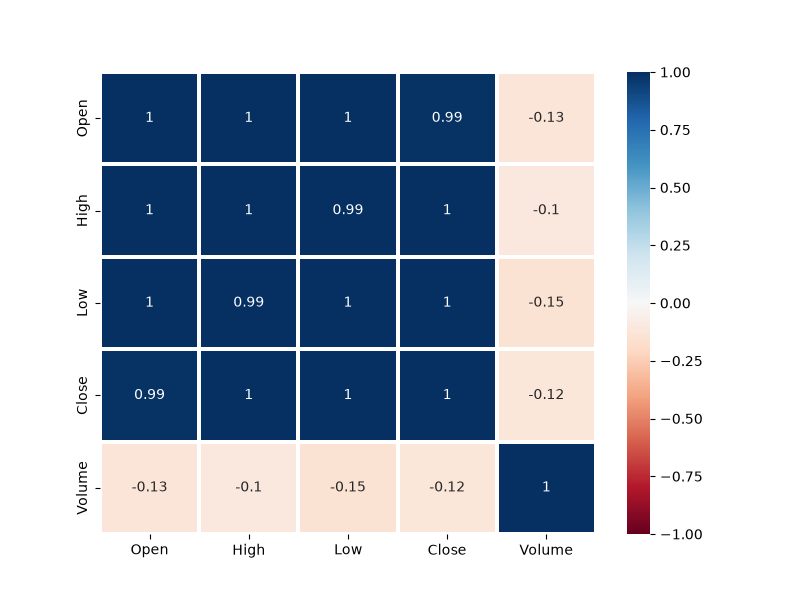

In [19]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='RdBu', vmin=-1, vmax=1, center=0,linewidths= 1.5)
plt.show()

*Interpretation*:
 - +1: perfect positive relationship
-   0: no linear relationship
-  -1: perfect negative relationship

*Financial Interpretation*: Highly correlated price variables often contain similar information, whereas volume may provide additional insight into market participation and liquidity.

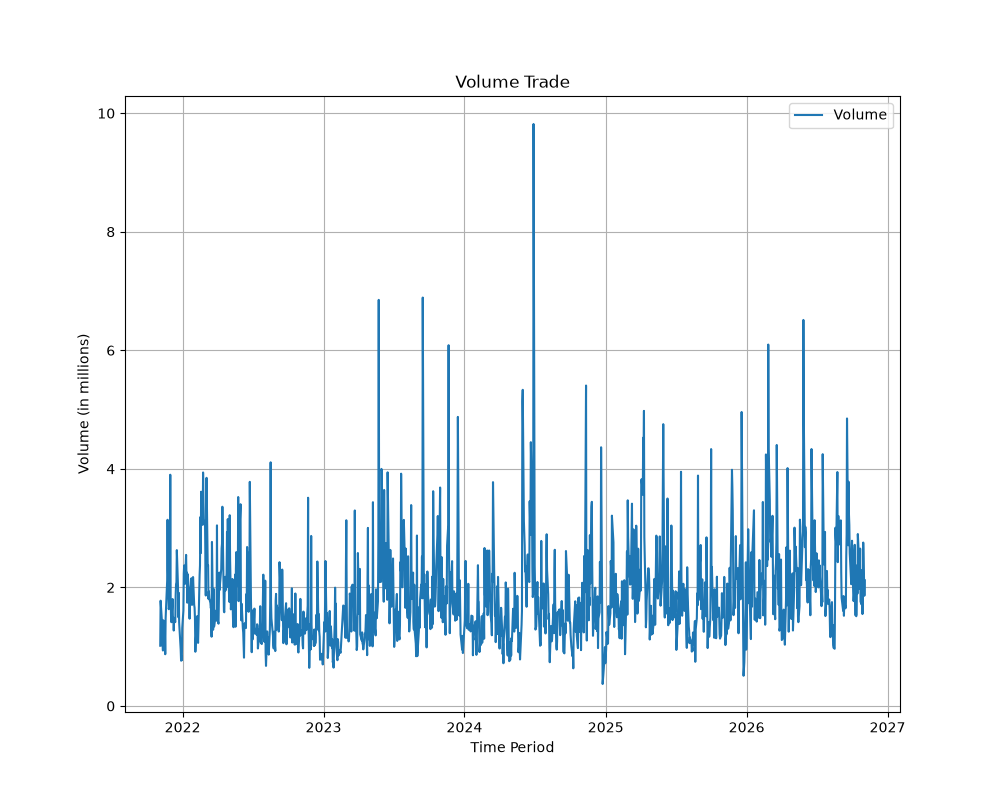

In [20]:
scaled_volume = df['Volume'] / 1_000_000

plt.figure(figsize=(10,8))
plt.plot(df['Date'],scaled_volume,label='Volume')
plt.title('Volume Trade')
plt.ylabel('Volume (in millions)')
plt.xlabel('Time Period')
plt.grid(True)
plt.legend()
plt.show()

The trading volume values were scaled down to millions to improve readability and make visualization easier.

This transformation does not result in information loss because it is reversible:

*Original Volume= Displayed Volume \ 1,000,000*

The original dataset remains unchanged; scaling is applied only during visualization.

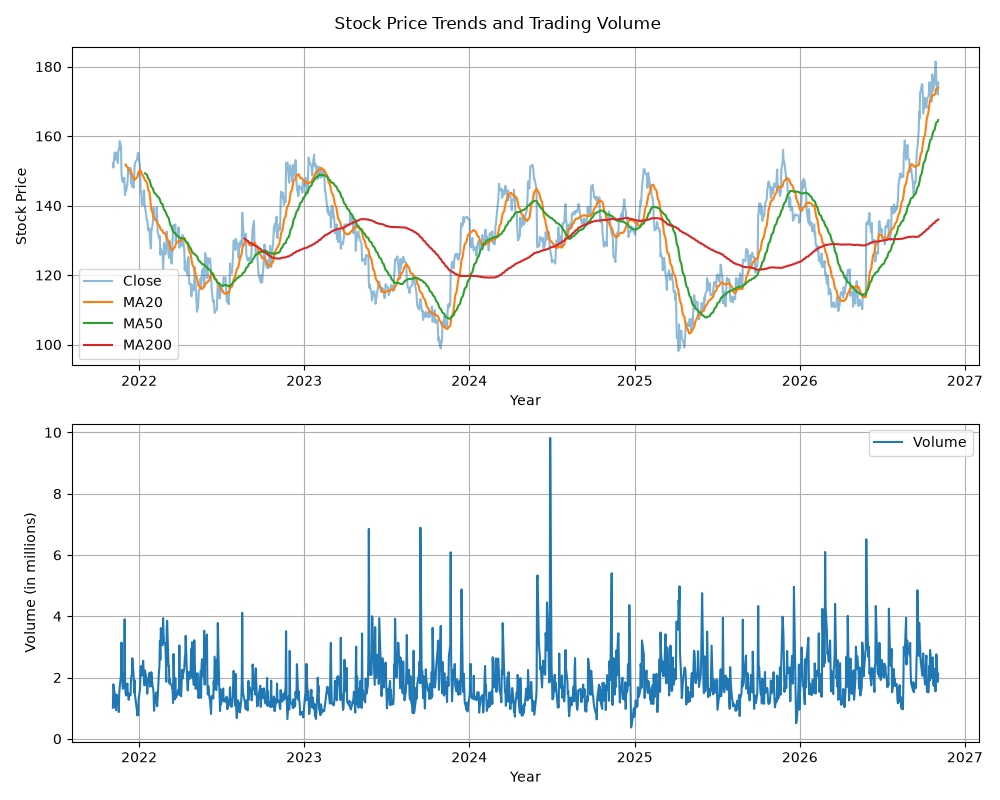

In [21]:
plt.figure(figsize=(10,8))

# 1st figure
plt.subplot(2,1,1)
plt.plot(df['Date'],df['Close'],label='Close',alpha = 0.5)
plt.plot(df['Date'],df['MA20'],label='MA20')
plt.plot(df['Date'],df['MA50'],label='MA50')
plt.plot(df['Date'],df['MA200'],label='MA200')
plt.xlabel('Year')
plt.ylabel('Stock Price')
plt.grid(True)
plt.legend()



# 2nd figure
plt.subplot(2,1,2)
plt.plot(df['Date'],scaled_volume,label='Volume')
plt.grid(True)
plt.xlabel('Year')
plt.ylabel('Volume (in millions)')
plt.legend()



plt.suptitle('Stock Price Trends and Trading Volume ')
plt.tight_layout()
plt.show()

Trading volume experienced significant spikes during mid-2024, coinciding with periods of relatively low stock prices.Several other can also be observed during other peak trading whenever the price dipped post-mid 2024.

This indicates increased trading activity during periods of price weakness. Such behavior may reflect heightened market interest, selling pressure, or potential accumulation.

However, volume alone cannot establish the direction of investor positioning or determine which investor groups benefited from these movements.

In [22]:
def calculate_adv( # 
    dataset: pd.DataFrame,
    period: int = 1
    ) -> pd.DataFrame:
    """Calculates Average Daily Volume over a specified rolling window (might contain missing values depending on period).

    Args:
        dataset (pd.DataFrame): a pandas dataframe
        period (int): int type. default at '1'

    Raises:
        ValueError: period is less than or equal to zero, or dates are not monotonically increasing.
        validate_dataframe (function): raises errors if dataset is empty or not a pandas dataframe
        TypeError: period is Boolean or not an integer. 
        
    Returns:
        pd.DataFrame: a pandas dataframe
    """
    
    validate_dataframe(dataset)
    
    convert_date(dataset,'Date') # default error = 'coerce'
    
    # period checks
    if isinstance(period,bool) or not isinstance(period,int):
        raise TypeError(f"period must be an integer, got {type(period).__name__}")
    if period <= 0:
        raise ValueError("period must be greater than 0 ")
    
    # important checks before daily average
    if not check_monotonic(dataset):
        raise ValueError('The dataframe must be monotonically increasing')
    
    # duplicate check 
    duplicate_date_check(dataset)
    
    dataset[f'ADV{period}'] = dataset['Volume'].rolling(window=period).mean()    
    
    return dataset

In [23]:
calculate_adv(df,20)
calculate_adv(df,200)
calculate_adv(df,100)
calculate_adv(df,50)

df.groupby(
    ['Date','Volume',"ADV20",'ADV200','ADV100','ADV50'],
    dropna=False
).size().reset_index()

,Date,Volume,ADV20,ADV200,ADV100,ADV50,0
0,2021-11-04,1015800,NaN,NaN,NaN,NaN,1
1,2021-11-05,1775500,NaN,NaN,NaN,NaN,1
2,2021-11-08,1467000,NaN,NaN,NaN,NaN,1
3,2021-11-09,1021000,NaN,NaN,NaN,NaN,1
4,2021-11-10,1093200,NaN,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...
1249,2026-10-28,1550400,2114915.0,2268901.0,2242749.0,2436758.0,1
1250,2026-10-29,1824800,2066795.0,2265058.0,2243546.0,2413130.0,1
1251,2026-10-30,2756400,2090110.0,2270419.5,2248027.0,2411652.0,1
1252,2026-11-02,1858800,2094605.0,2271338.5,2246696.0,2394222.0,1


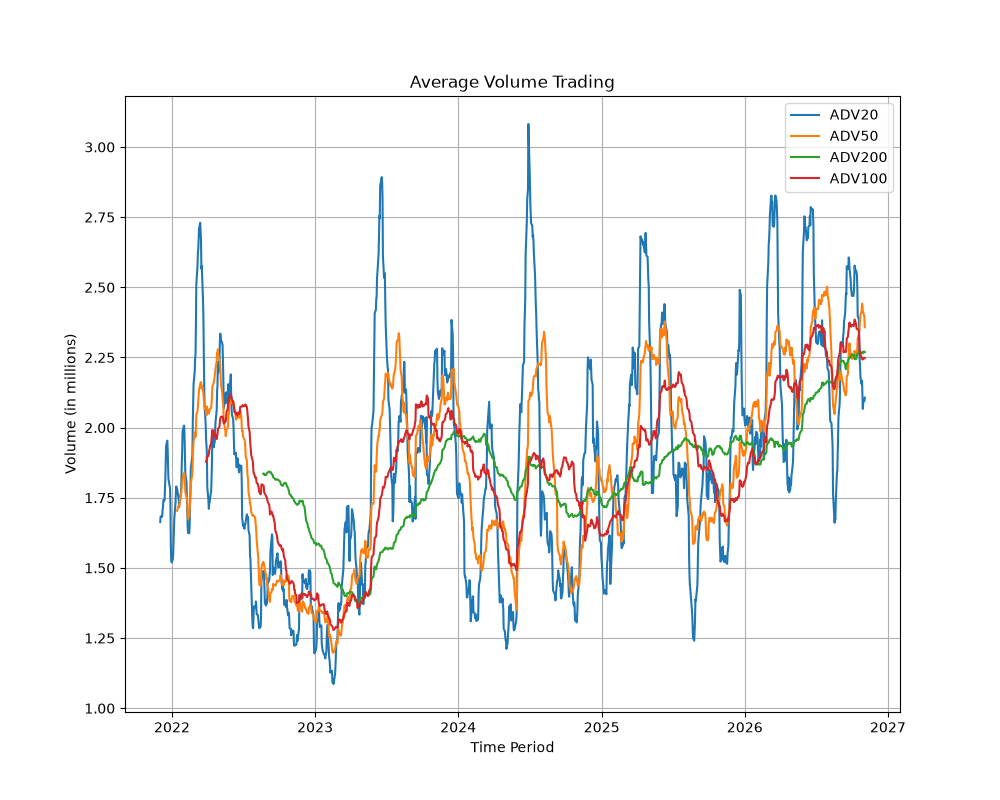

In [24]:
scaled_adv20 = df['ADV20'] / 1_000_000
scaled_adv200 = df['ADV200'] / 1_000_000
scaled_adv50 = df['ADV50'] / 1_000_000
scaled_adv100 = df['ADV100'] / 1_000_000


plt.figure(figsize=(10,8))
#plt.plot(df['Date'],scaled_volume, label= 'Volume')
plt.plot(df['Date'],scaled_adv20,label = 'ADV20')
plt.plot(df['Date'],scaled_adv50,label = 'ADV50')
plt.plot(df['Date'],scaled_adv200,label = 'ADV200')
plt.plot(df['Date'],scaled_adv100,label = 'ADV100')
plt.grid(True)
plt.xlabel('Time Period')
plt.ylabel('Volume (in millions)')
plt.title('Average Volume Trading')
#plt.savefig(r'C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\outputs\visualization\avg_volume_trading')
plt.legend()
plt.show()


*Average Volume Trading*

The below observations can be made from the chart: 

`ADV20`:
- it is the most volatile as it responds quickly to daily trading volume.
- Short-Term volume spikes are reflected more prominently.
- It is more sensitive due to market change

`ADV50`:
- It captures medium-term changes.
- Individual volume spikes have less influence.
- It responds more slowly than ADV20.

`ADV100 and ADV200`:.
- They incorporate more historical observations.
- They are considerably smoother
- Short-term fluctuations have less influence.
- They provide a broader picture of historical trading activity.

`Financial Interpretation`:

- Short-term fluctuations in ADV20 indicate that trading activity is sensitive to changes in market participation and noise.
- ADV50 provides a more balanced view of trading activity by reducing the influence of individual volume spikes.
- ADV100 and ADV200 provide a broader perspective on historical trading activity and help identify longer-term volume trends.
- A decline in shorter-term ADV relative to longer-term ADV may indicate reduced recent trading activity compared to its historical average.
- High ADV: Generally indicates greater liquidity and trading activity compared with stocks having lower ADV.
- Low ADV: Generally indicates lower liquidity and trading activity, potentially making it harder to execute large

However, these indicators alone cannot establish whether a stock has high or low liquidity, as liquidity also depends on other factors.

In [25]:
ratio = df['ADV20'] / df['ADV200']

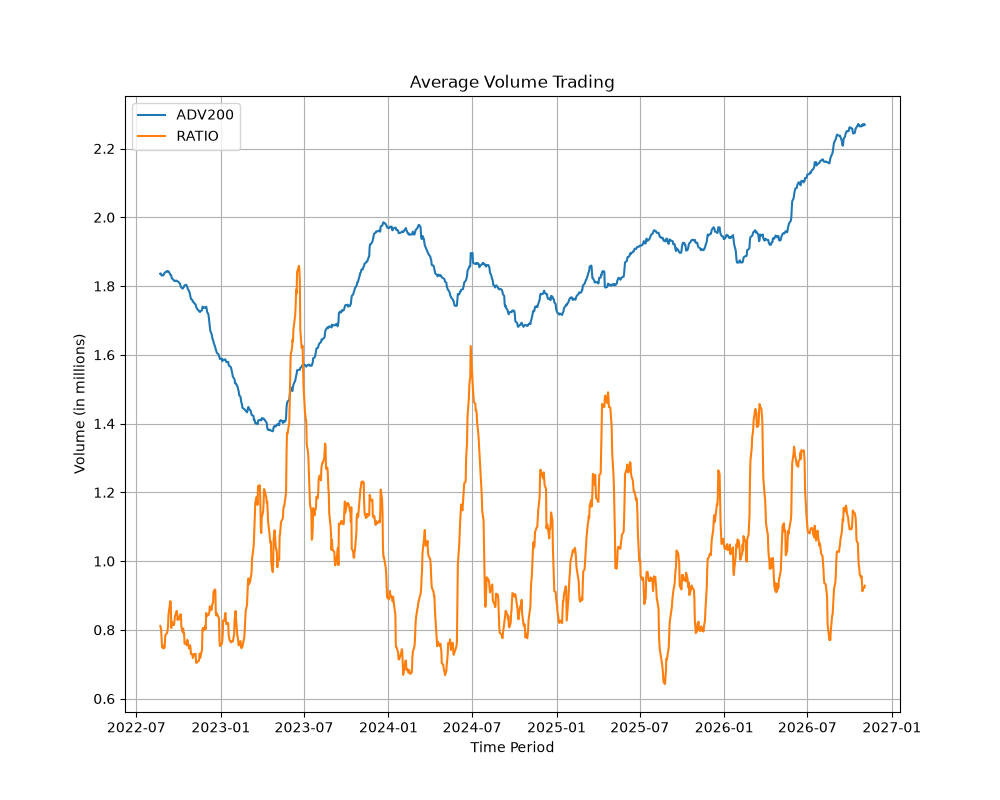

In [26]:
plt.figure(figsize=(10,8))

#plt.plot(df['Date'],scaled_volume, label= 'Volume')
#plt.plot(df['Date'],scaled_adv20,label = 'ADV20')
plt.plot(df['Date'],scaled_adv200,label = 'ADV200')
plt.plot(df['Date'],ratio,label = 'RATIO')
plt.grid(True)
plt.xlabel('Time Period')
plt.ylabel('Volume (in millions)')
plt.title('Average Volume Trading')
plt.legend()
plt.show()

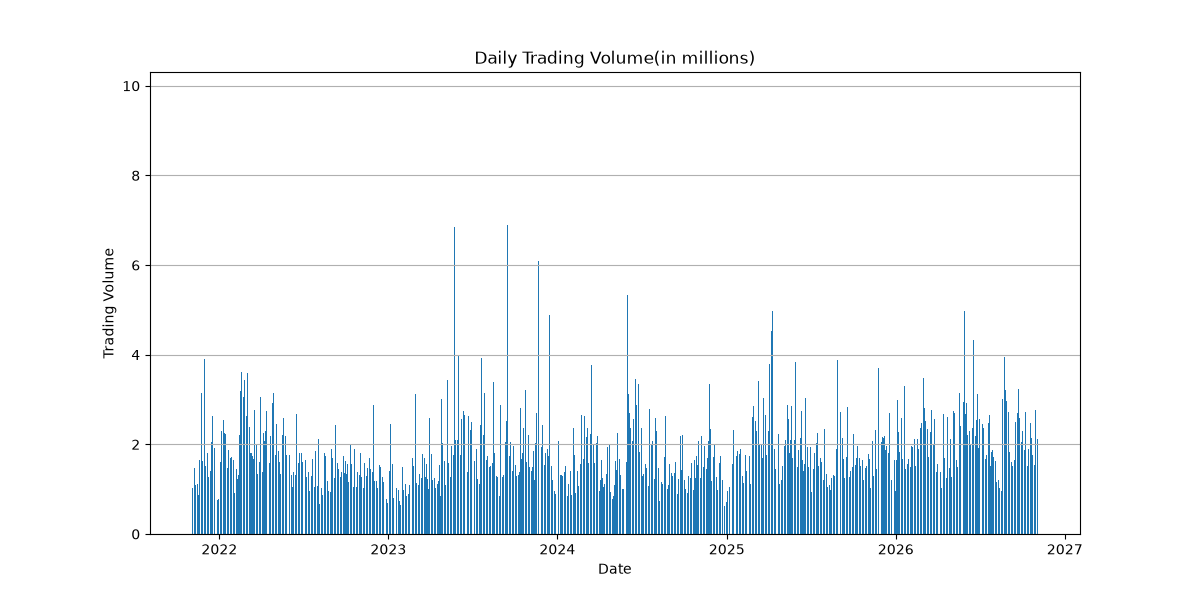

In [27]:
plt.figure(figsize=(12, 6))

plt.bar(df['Date'], scaled_volume,width=1)

plt.xlabel('Date')
plt.ylabel('Trading Volume')
plt.title('Daily Trading Volume(in millions)')
#plt.savefig(r'C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\outputs\visualization\daily_volume_trading')
plt.grid(axis='y')
plt.show()

*Daily Trading Volume Analysis*

The daily trading volume bar chart appears visually dense due to the high frequency of observations across the selected period. However, some patterns can still be identified.

Trading volume appears relatively elevated during early and late 2023, followed by a decline toward the end of the observed period.

Although the chart does not reveal a particularly distinct or consistent pattern, it provides a basic overview of changes in daily trading activity over time.

In [28]:
def volume_spike(
    dataset: pd.DataFrame
    ) -> pd.DataFrame:
    
    """Produces a dataset with Volume Spike

    Args:
        dataset (pd.DataFrame): a pandas data frame of OHLCV stock data
    
    Raises:
        validate_dataframe (function): raises errors if dataset is empty or not a pandas dataframe
        
    Returns:
        _type_: a pandas dataframe 
    """
    
    validate_dataframe(dataset)
    column_check(dataset)

    volume_df = dataset[['Volume', 'ADV20']].where(dataset['Volume'] > (2 * dataset['ADV20']), np.nan).dropna() # can be used in returned if only to view the dataframe
    
    dataset['Volume_Spike'] = dataset['Volume'].where(
    
    dataset['Volume'] > (2 * dataset['ADV20']),
    np.nan)
    
    return dataset



In [29]:
volume_spike(df)

,Close,High,Low,Open,Volume,Ticker,Date,MA20,MA50,MA200,ADV20,ADV200,ADV100,ADV50,Volume_Spike
0,152.12,153.35,150.87,152.32,1015800,A,2021-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,150.92,151.31,147.08,151.07,1775500,A,2021-11-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,155.29,155.49,151.05,151.49,1467000,A,2021-11-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,154.20,156.53,153.92,155.29,1021000,A,2021-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,153.69,154.36,150.58,153.62,1093200,A,2021-11-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1249,181.48,182.99,176.77,177.18,1550400,A,2026-10-28,172.51,163.05,135.35,2114915.0,2268901.0,2242749.0,2436758.0,NaN
1250,181.15,182.72,179.65,182.00,1824800,A,2026-10-29,173.24,163.56,135.53,2066795.0,2265058.0,2243546.0,2413130.0,NaN
1251,174.87,180.98,173.38,180.98,2756400,A,2026-10-30,173.61,163.94,135.68,2090110.0,2270419.5,2248027.0,2411652.0,NaN
1252,171.99,176.77,171.51,176.13,1858800,A,2026-11-02,173.66,164.21,135.82,2094605.0,2271338.5,2246696.0,2394222.0,NaN


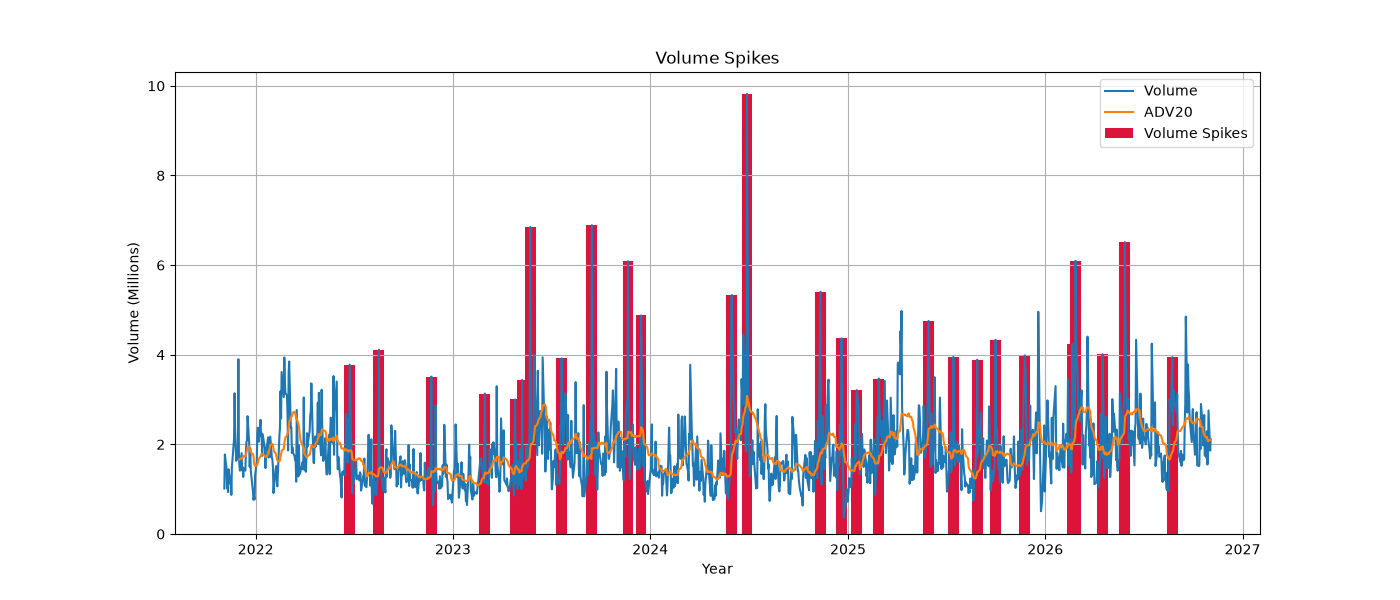

In [30]:
scaled_volume_spike = df['Volume_Spike'] / 1_000_000

plt.figure(figsize=(14, 6))

plt.bar(df['Date'], scaled_volume_spike, label='Volume Spikes',width=20,color = 'CRIMSON')
plt.plot(df['Date'], scaled_volume, label='Volume')
plt.plot(df['Date'], scaled_adv20, label='ADV20')

plt.xlabel('Year')
plt.ylabel('Volume (Millions)')
plt.title('Volume Spikes')
plt.legend()
plt.grid(True,)
#plt.savefig(r'C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\outputs\visualization\volume_spike')
plt.show()

The purpose of this visualization helps identify abnormal trading activity and provides insight into whether significant market events were accompanied by unusually high investor participation.

In [31]:
def rvol(
    dataset: pd.DataFrame
    ) -> pd.DataFrame:
    """Appends Relative Volume Analysis on the provided dataframe

    Args:
        dataset (pd.DataFrame): pandas dataframe

    Returns:
        pd.DataFrame: pandas dataframe
    """
    validate_dataframe(dataset)
    column_check(dataset)
    
    dataset['RVOL'] = dataset['Volume'] / dataset['ADV20']
    
    return dataset

In [32]:
round_float(rvol(df))

,Close,High,Low,Open,Volume,Ticker,Date,MA20,MA50,MA200,ADV20,ADV200,ADV100,ADV50,Volume_Spike,RVOL
0,152.12,153.35,150.87,152.32,1015800,A,2021-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,150.92,151.31,147.08,151.07,1775500,A,2021-11-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,155.29,155.49,151.05,151.49,1467000,A,2021-11-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,154.20,156.53,153.92,155.29,1021000,A,2021-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,153.69,154.36,150.58,153.62,1093200,A,2021-11-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1249,181.48,182.99,176.77,177.18,1550400,A,2026-10-28,172.51,163.05,135.35,2114915.0,2268901.0,2242749.0,2436758.0,NaN,0.73
1250,181.15,182.72,179.65,182.00,1824800,A,2026-10-29,173.24,163.56,135.53,2066795.0,2265058.0,2243546.0,2413130.0,NaN,0.88
1251,174.87,180.98,173.38,180.98,2756400,A,2026-10-30,173.61,163.94,135.68,2090110.0,2270419.5,2248027.0,2411652.0,NaN,1.32
1252,171.99,176.77,171.51,176.13,1858800,A,2026-11-02,173.66,164.21,135.82,2094605.0,2271338.5,2246696.0,2394222.0,NaN,0.89


In [33]:
df.loc[df['RVOL'] > 1, ['Date', 'RVOL']]

,Date,RVOL
21,2021-12-06,1.07
27,2021-12-14,1.05
28,2021-12-15,1.13
29,2021-12-16,1.11
30,2021-12-17,1.36
...,...,...
1242,2026-10-19,1.04
1245,2026-10-22,1.20
1248,2026-10-27,1.06
1251,2026-10-30,1.32


In [34]:
df.loc[df['RVOL'] > 3, ['Date', 'RVOL']]

,Date,RVOL
389,2023-05-24,3.61
467,2023-09-15,3.61
644,2024-05-30,3.31
645,2024-05-31,3.03
664,2024-06-28,3.19


In [35]:
(df.loc[df['RVOL'] > 2, ['Date', 'RVOL']])

,Date,RVOL
159,2022-06-24,2.03
196,2022-08-17,2.82
264,2022-11-22,2.51
330,2023-03-01,2.31
369,2023-04-26,2.02
378,2023-05-09,2.28
389,2023-05-24,3.61
428,2023-07-21,2.13
467,2023-09-15,3.61
514,2023-11-21,2.67


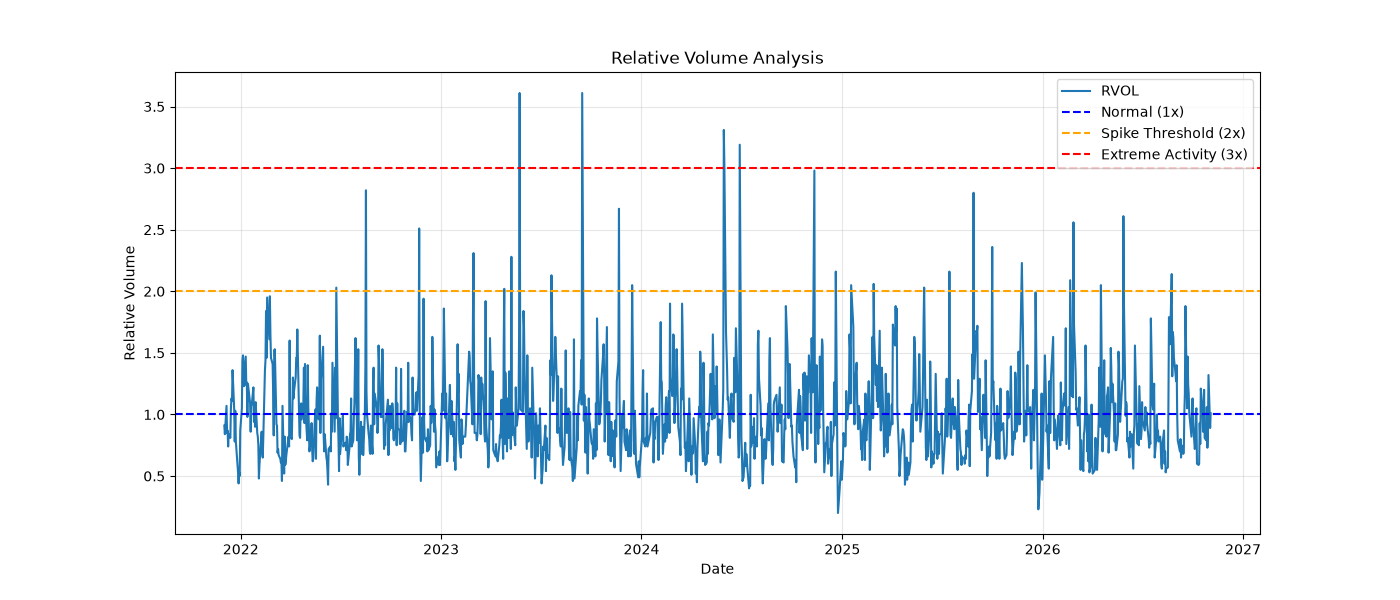

In [36]:
plt.figure(figsize=(14, 6))

plt.plot(df['Date'], df['RVOL'], label='RVOL')

plt.axhline(1, color='blue', linestyle='--', label='Normal (1x)')
plt.axhline(2, color='orange', linestyle='--', label='Spike Threshold (2x)')
plt.axhline(3, color='red', linestyle='--', label='Extreme Activity (3x)')

plt.xlabel('Date')
plt.ylabel('Relative Volume')
plt.title('Relative Volume Analysis')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

`Relative Volume Analysis:`

The Relative Volume Analysis indicates that extreme trading activity (RVOL > 3) was observed on 4 occasions, while trading volume exceeded the defined spike threshold (RVOL > 2) on 28 occasions for the selected stock.

These observations suggest that periods of unusually high trading activity occurred throughout the study period, although their frequency and intensity varied.


*Financial Interpretation*:

The observed volume spikes indicate periods of significantly elevated trading activity, suggesting increased market participation and investor interest in the selected stock.

The 28 occurrences above the 2× ADV20 threshold indicate that trading activity substantially exceeded its recent average on multiple occasions. Furthermore, the 4 extreme occurrences above 3× ADV20 suggest isolated periods of particularly intense trading activity.

Such increases in trading volume may be associated with:

- Earnings announcements and corporate disclosures.
- Significant economic or financial news.
- Changes in investor sentiment.
- Institutional trading activity.
- Market uncertainty or unexpected events.

These observations highlight periods of unusual market activity that may warrant further investigation alongside price movements and relevant market events.

However, elevated trading volume alone does not establish whether market sentiment was bullish or bearish, nor does it confirm the presence of institutional activity or specific news events.

In [37]:
def calculate_returns(
    dataset: pd.DataFrame,
) -> pd.DataFrame:
    """Calculates Daily Return of the stock dataset and appends the column

    Args:
        dataset (pd.DataFrame): pandas dataframe

    Returns:
        pd.DataFrame: pandas dataframe
    """
    validate_dataframe(dataset)
    column_check(dataset)    
    
    dataset['Daily_Return'] = dataset['Close'].pct_change() * 100
    
    
    
    # monthly return
    monthly_df = dataset.resample('ME', on='Date')[['Close']].last()

    monthly_returns = monthly_df['Close'].pct_change() * 100

    monthly_dates = dataset.groupby(
        dataset['Date'].dt.to_period('M')
    )['Date'].max()

    monthly_return_map = pd.Series(
        monthly_returns.values,
        index=monthly_dates.values
    )

    dataset['Monthly Return'] = dataset['Date'].map(monthly_return_map)
        
    # yearly return
    yearly_df = dataset.resample('YE', on='Date')[['Close']].last()

    yearly_returns = yearly_df['Close'].pct_change() * 100

    yearly_dates = dataset.groupby(
        dataset['Date'].dt.to_period('Y')
    )['Date'].max()

    yearly_return_map = pd.Series(
        yearly_returns.values,
        index=yearly_dates.values
    )
    
    dataset['Yearly Return'] = dataset['Date'].map(yearly_return_map)
    
    return dataset

In [38]:
round_float(calculate_returns(df))

,Close,High,Low,Open,Volume,Ticker,Date,MA20,MA50,MA200,ADV20,ADV200,ADV100,ADV50,Volume_Spike,RVOL,Daily_Return,Monthly Return,Yearly Return
0,152.12,153.35,150.87,152.32,1015800,A,2021-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,150.92,151.31,147.08,151.07,1775500,A,2021-11-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.79,NaN,NaN
2,155.29,155.49,151.05,151.49,1467000,A,2021-11-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.90,NaN,NaN
3,154.20,156.53,153.92,155.29,1021000,A,2021-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.70,NaN,NaN
4,153.69,154.36,150.58,153.62,1093200,A,2021-11-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.33,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1249,181.48,182.99,176.77,177.18,1550400,A,2026-10-28,172.51,163.05,135.35,2114915.0,2268901.0,2242749.0,2436758.0,NaN,0.73,2.25,NaN,NaN
1250,181.15,182.72,179.65,182.00,1824800,A,2026-10-29,173.24,163.56,135.53,2066795.0,2265058.0,2243546.0,2413130.0,NaN,0.88,-0.18,NaN,NaN
1251,174.87,180.98,173.38,180.98,2756400,A,2026-10-30,173.61,163.94,135.68,2090110.0,2270419.5,2248027.0,2411652.0,NaN,1.32,-3.47,1.64,NaN
1252,171.99,176.77,171.51,176.13,1858800,A,2026-11-02,173.66,164.21,135.82,2094605.0,2271338.5,2246696.0,2394222.0,NaN,0.89,-1.65,NaN,NaN


In [39]:
df.groupby(
    ['Date','Close','Daily_Return','Monthly Return','Yearly Return'],
    dropna=False
).size().reset_index()

,Date,Close,Daily_Return,Monthly Return,Yearly Return,0
0,2021-11-04,152.12,NaN,NaN,NaN,1
1,2021-11-05,150.92,-0.79,NaN,NaN,1
2,2021-11-08,155.29,2.90,NaN,NaN,1
3,2021-11-09,154.20,-0.70,NaN,NaN,1
4,2021-11-10,153.69,-0.33,NaN,NaN,1
...,...,...,...,...,...,...
1249,2026-10-28,181.48,2.25,NaN,NaN,1
1250,2026-10-29,181.15,-0.18,NaN,NaN,1
1251,2026-10-30,174.87,-3.47,1.64,NaN,1
1252,2026-11-02,171.99,-1.65,NaN,NaN,1


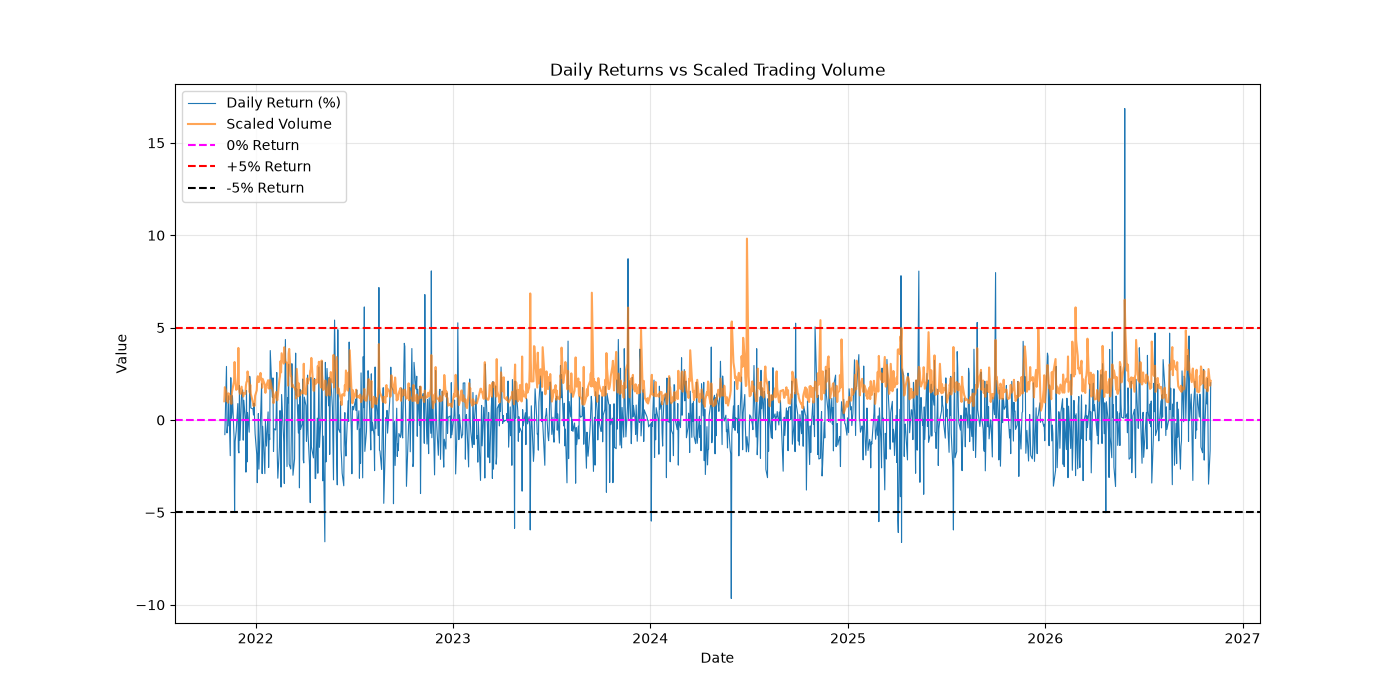

In [ ]:
plt.figure(figsize=(14, 7))

plt.plot(
    df['Date'],
    df['Daily_Return'],
    label='Daily Return (%)',
    linewidth=0.8
)

plt.plot(
    df['Date'],
    scaled_volume,
    label='Scaled Volume',
    alpha=0.7
)

plt.axhline(0, color='magenta', linestyle='--', label='0% Return')
plt.axhline(5, color='red', linestyle='--', label='+5% Return')
plt.axhline(-5, color='black', linestyle='--', label='-5% Return')

plt.title('Daily Returns vs Scaled Trading Volume')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(alpha=0.3)
#plt.savefig(r'C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\outputs\visualization\Daily_Returns_vs_Scaled_Trading Volume')
plt.show()

### Key Observations

1. **Volatility Regimes:** Early–mid 2024 shows relatively concentrated daily returns, while 2025–2026 exhibits more frequent price spikes and elevated trading activity.

2. **Price-Volume Confirmation:** Positive or negative return spikes accompanied by elevated relative volume indicate increased market participation during significant price movements.

3. **Unusual Volume Events:** A notable ~10x relative-volume spike in mid-2024 occurred with limited price movement, potentially indicating opposing buying and selling pressure or large transactions.

**Financial Interpretation:** Price movements combined with relative volume provide better insight into market activity than either indicator independently. These observations warrant further investigation rather than establishing definitive market behaviour.